# WATERWATCH AI 💧🤖
## Phase 1 & Phase 3: Dataset Inspection & Exploratory Data Analysis (EDA)
**Role:** Member 1 – Data & ML Engineer  
**Project:** Explainable AI-Based Water Potability Prediction and Community Risk Monitoring System  

---

### Project Overview
The **WATERWATCH AI** system predicts water potability using physicochemical water-quality parameters. This notebook performs **Phase 1 (Dataset Collection and Inspection)** and **Phase 3 (Exploratory Data Analysis)** on the Kaggle Water Potability dataset.

### Dataset Description (Report Summary)
- **Observations:** 3,276 water samples
- **Input Features (9):** `ph`, `Hardness`, `Solids`, `Chloramines`, `Sulfate`, `Conductivity`, `Organic_carbon`, `Trihalomethanes`, `Turbidity` (all continuous `float64`)
- **Target Label (1):** `Potability` (`0 = Non-Potable`, `1 = Potable`)
- **Missing Values:** Localized to 3 features: `Sulfate` (23.84%), `ph` (14.99%), and `Trihalomethanes` (4.95%)
- **Class Balance:** 1,998 Non-Potable (60.99%) vs. 1,278 Potable (39.01%) — mild class imbalance

### 1. Library Imports & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set aesthetic visual defaults
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams['figure.dpi'] = 120

# Load dataset (relative path)
import os
# Robust dataset path: checks data/raw/ before falling back
DATA_PATH = '../data/raw/water_potability.csv' if os.path.exists('../data/raw/water_potability.csv') else ('data/raw/water_potability.csv' if os.path.exists('data/raw/water_potability.csv') else '../data/water_potability.csv')
df = pd.read_csv(DATA_PATH)
print(f"Dataset successfully loaded from: {DATA_PATH}")

# First 5 and Last 5 Records
print("=== FIRST FIVE RECORDS ===")
display(df.head())

print("\n=== LAST FIVE RECORDS ===")
display(df.tail())

Dataset successfully loaded from: ../data/raw/water_potability.csv
=== FIRST FIVE RECORDS ===


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0



=== LAST FIVE RECORDS ===


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,NaN,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,NaN,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,NaN,402.883113,11.168946,77.488213,4.708658,1
3275,7.874671,195.102299,17404.177061,7.509306,NaN,327.459760,16.140368,78.698446,2.309149,1


### 2. Dataset Dimensions, Schema & Data Types

In [2]:
print(f"Total Rows:    {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}\n")

print("--- Column Data Types & Non-Null Counts ---")
df.info()

Total Rows:    3276
Total Columns: 10

--- Column Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


### 3. Missing Value Analysis & Duplicate Audit

In [3]:
# Missing value counts and percentages
missing_count = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_pct.round(2)
})

print("=== MISSING VALUE SUMMARY ===")
display(missing_df[missing_df['Missing Count'] > 0])
print(f"Total Missing Cells Across Dataset: {df.isnull().sum().sum()}")

# Duplicate row check
dups = df.duplicated().sum()
print(f"\nTotal Duplicate Records: {dups}")
assert dups == 0, "Warning: Duplicate rows detected!"

=== MISSING VALUE SUMMARY ===


,Missing Count,Percentage (%)
ph,491,14.99
Sulfate,781,23.84
Trihalomethanes,162,4.95


Total Missing Cells Across Dataset: 1434

Total Duplicate Records: 0


### 4. 5-Number Summary & Target Class Distribution

In [4]:
# 5-Number Statistical Summary
print("=== STATISTICAL SUMMARY (5-Number Summary + Mean & Std) ===")
display(df.describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(2))

# Target Class Distribution
print("\n=== TARGET CLASS DISTRIBUTION ('Potability') ===")
class_counts = df['Potability'].value_counts()
class_pcts = (df['Potability'].value_counts(normalize=True) * 100).round(2)

class_dist = pd.DataFrame({
    'Count': class_counts,
    'Percentage (%)': class_pcts
}, index=[0, 1])
class_dist.index.name = 'Potability Class'
display(class_dist)

=== STATISTICAL SUMMARY (5-Number Summary + Mean & Std) ===


,mean,std,min,25%,50%,75%,max
ph,7.08,1.59,0.00,6.09,7.04,8.06,14.00
Hardness,196.37,32.88,47.43,176.85,196.97,216.67,323.12
Solids,22014.09,8768.57,320.94,15666.69,20927.83,27332.76,61227.20
Chloramines,7.12,1.58,0.35,6.13,7.13,8.11,13.13
Sulfate,333.78,41.42,129.00,307.70,333.07,359.95,481.03
Conductivity,426.21,80.82,181.48,365.73,421.88,481.79,753.34
Organic_carbon,14.28,3.31,2.20,12.07,14.22,16.56,28.30
Trihalomethanes,66.40,16.18,0.74,55.84,66.62,77.34,124.00
Turbidity,3.97,0.78,1.45,3.44,3.96,4.50,6.74
Potability,0.39,0.49,0.00,0.00,0.00,1.00,1.00



=== TARGET CLASS DISTRIBUTION ('Potability') ===


,Count,Percentage (%)
Potability Class,,
0,1998,60.99
1,1278,39.01


---
## Phase 3: Exploratory Data Analysis (6 Core Visualizations)

### Visualization 1: Target Class Distribution
- **Objective:** Evaluate class balance between potable (1) and non-potable (0) samples.
- **Interpretation:** The dataset contains 1,998 non-potable records (60.99%) and 1,278 potable records (39.01%).
- **Key Observation:** Mild class imbalance exists (~61:39). Stratified splitting is required to prevent sampling bias.
- **Conclusion:** Standard accuracy is misleading; evaluation must prioritize Precision, Recall, F1-Score, and ROC-AUC.

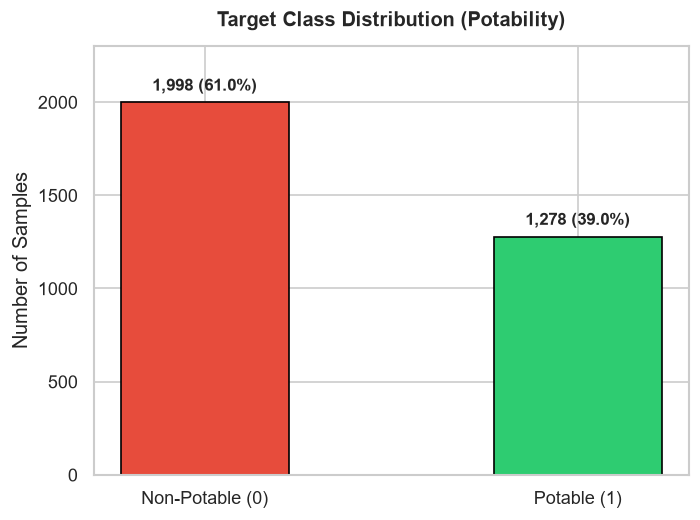

In [5]:
fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(['Non-Potable (0)', 'Potable (1)'], class_counts, color=['#e74c3c', '#2ecc71'], width=0.45, edgecolor='black')

for bar, count, pct in zip(bars, class_counts, class_pcts):
    height = bar.get_height()
    ax.annotate(f'{count:,} ({pct:.1f}%)',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords='offset points',
                ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title('Target Class Distribution (Potability)', fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel('Number of Samples')
ax.set_ylim(0, 2300)
plt.tight_layout()
plt.show()

### Visualization 2: Feature Distribution Histograms
- **Objective:** Inspect distribution shape, central tendency, and skewness across all 9 input features.
- **Interpretation:** 8 of the 9 features exhibit roughly normal (Gaussian) bell curves. `Solids` shows moderate positive skew.
- **Key Observation:** Gaussian distribution holds well for continuous variables, supporting Gaussian Naive Bayes modeling assumptions.
- **Conclusion:** Feature values span disparate magnitudes (e.g., `Solids` in tens of thousands vs. `ph` 0-14), mandating feature scaling.

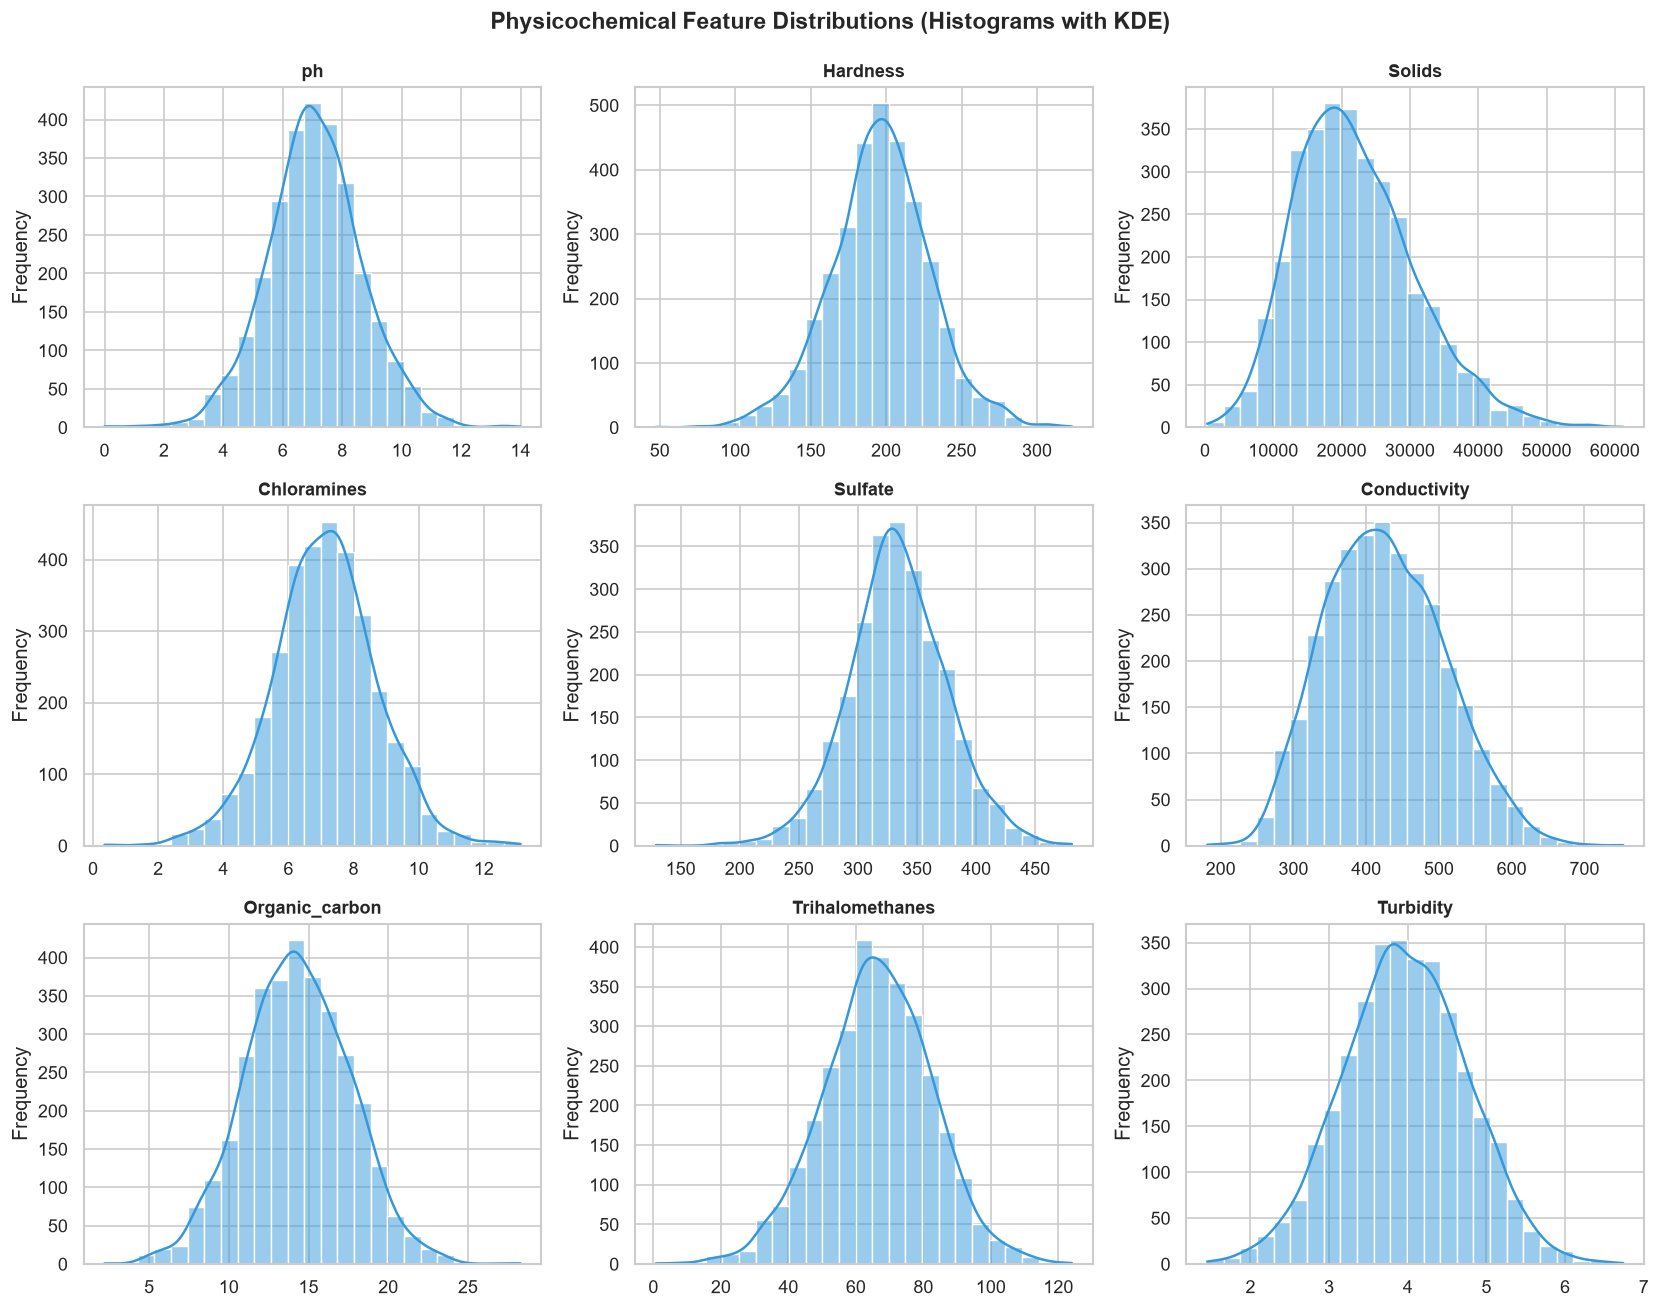

In [6]:
features = df.columns.drop('Potability')
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[i], color='#3498db', edgecolor='white', bins=25)
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frequency')

plt.suptitle('Physicochemical Feature Distributions (Histograms with KDE)', fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

### Visualization 3: Boxplots for Numerical Features (Outlier Investigation)
- **Objective:** Visualize feature dispersion, IQR spread, and identify extreme observations.
- **Interpretation:** Features are standardized to zero mean and unit variance ($Z$-scores) to compare spreads simultaneously.
- **Key Observation:** Outliers exist symmetrically beyond the $1.5 \times IQR$ threshold for all features, but outlier rates are low (0.34% to 2.53%).
- **Conclusion:** Statistical outliers identified by the 1.5 x IQR rule fall within plausible chemical limits for untreated water sources. Because severe contamination events naturally produce extreme concentrations, these observations are retained to preserve critical screening signals rather than discarded as measurement noise.

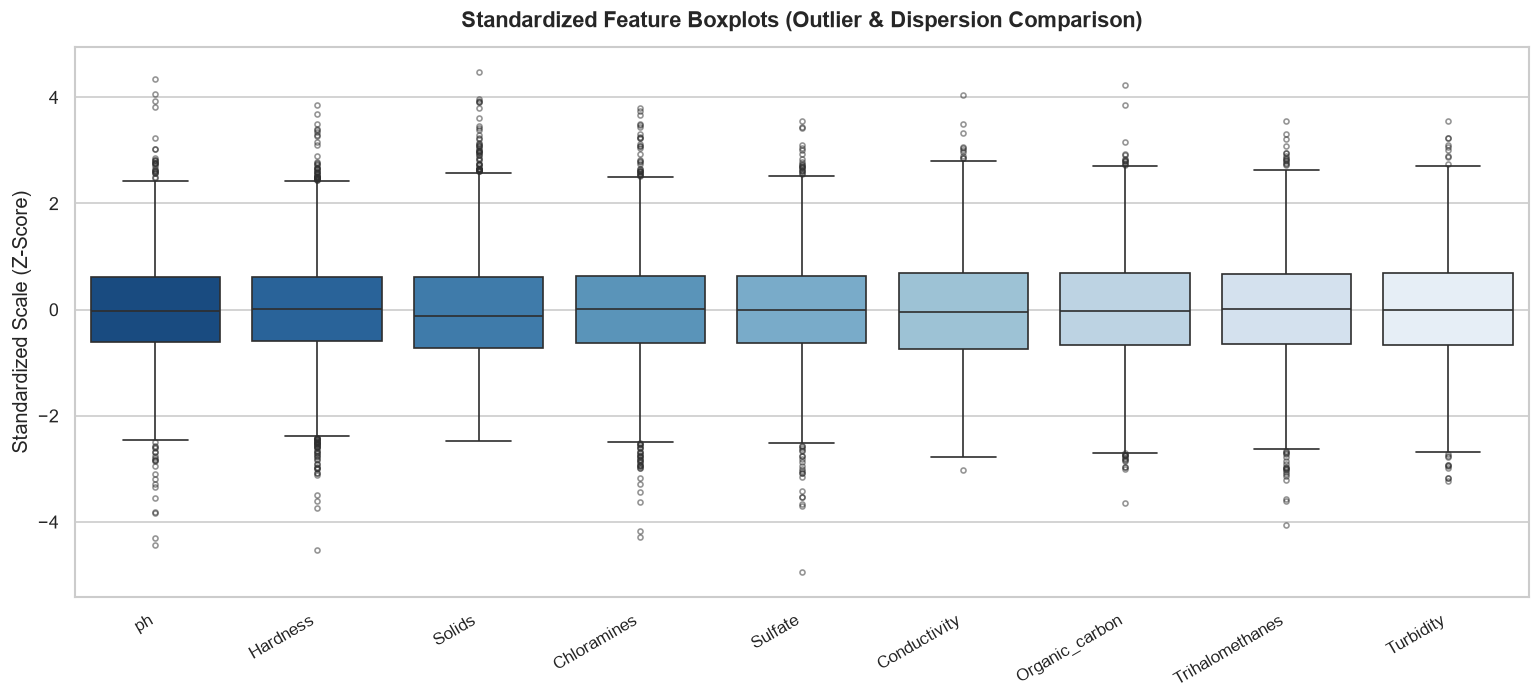

In [7]:
# Z-score standardization for comparative visual plotting
norm_df = (df[features] - df[features].mean()) / df[features].std()

fig, ax = plt.subplots(figsize=(13, 6))
sns.boxplot(data=norm_df, ax=ax, palette='Blues_r', flierprops=dict(marker='o', markersize=3, alpha=0.5))
ax.set_title('Standardized Feature Boxplots (Outlier & Dispersion Comparison)', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Standardized Scale (Z-Score)')
ax.set_xticks(range(len(features)))
ax.set_xticklabels(features, rotation=30, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

### Visualization 4: Feature Correlation Matrix Heatmap
- **Objective:** Investigate collinearity among features and linear correlation with target `Potability`.
- **Interpretation:** Pearson correlation between all predictors and `Potability` is virtually zero ($-0.030 \le r \le +0.034$).
- **Key Observation:** No single chemical parameter linearly distinguishes potable from non-potable water.
- **Conclusion:** Negligible linear correlation coefficients (|r| <= 0.034 with Potability) confirm that individual features possess virtually zero bivariate linear separating power. Effective prediction requires multi-variable non-linear algorithms (such as Decision Trees) or joint probabilistic classifiers (such as Gaussian Naive Bayes) that capture multidimensional feature interactions.

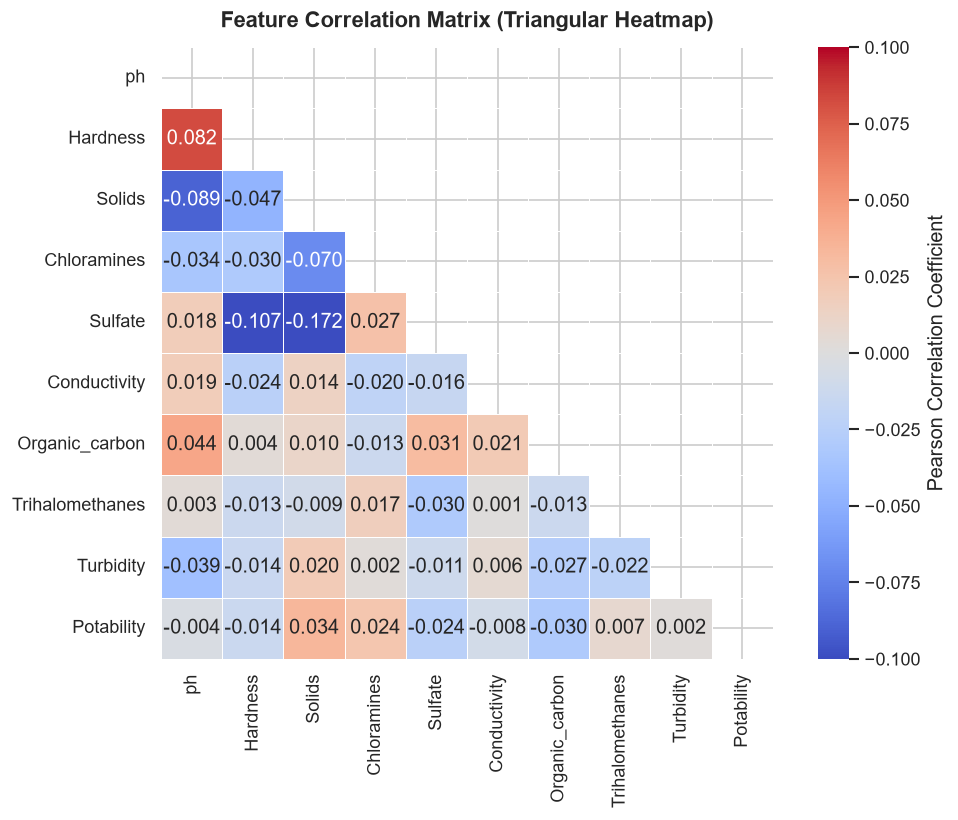

In [8]:
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt='.3f', cmap='coolwarm', vmin=-0.1, vmax=0.1, center=0,
            square=True, linewidths=0.5, cbar_kws={'label': 'Pearson Correlation Coefficient'}, ax=ax)
ax.set_title('Feature Correlation Matrix (Triangular Heatmap)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

### Visualization 5: Feature-Wise Distributions Conditioned on Potability
- **Objective:** Compare probability density functions $P(X_i | \text{Potable})$ vs. $P(X_i | \text{Non-Potable})$.
- **Interpretation:** The density curves for Potable (green) and Non-Potable (red) almost completely overlap for every individual parameter.
- **Key Observation:** Univariate separation is impossible. Potability is determined by multi-parameter chemical interactions.
- **Conclusion:** Demonstrates the explicit need for machine learning to detect high-dimensional non-linear boundaries.

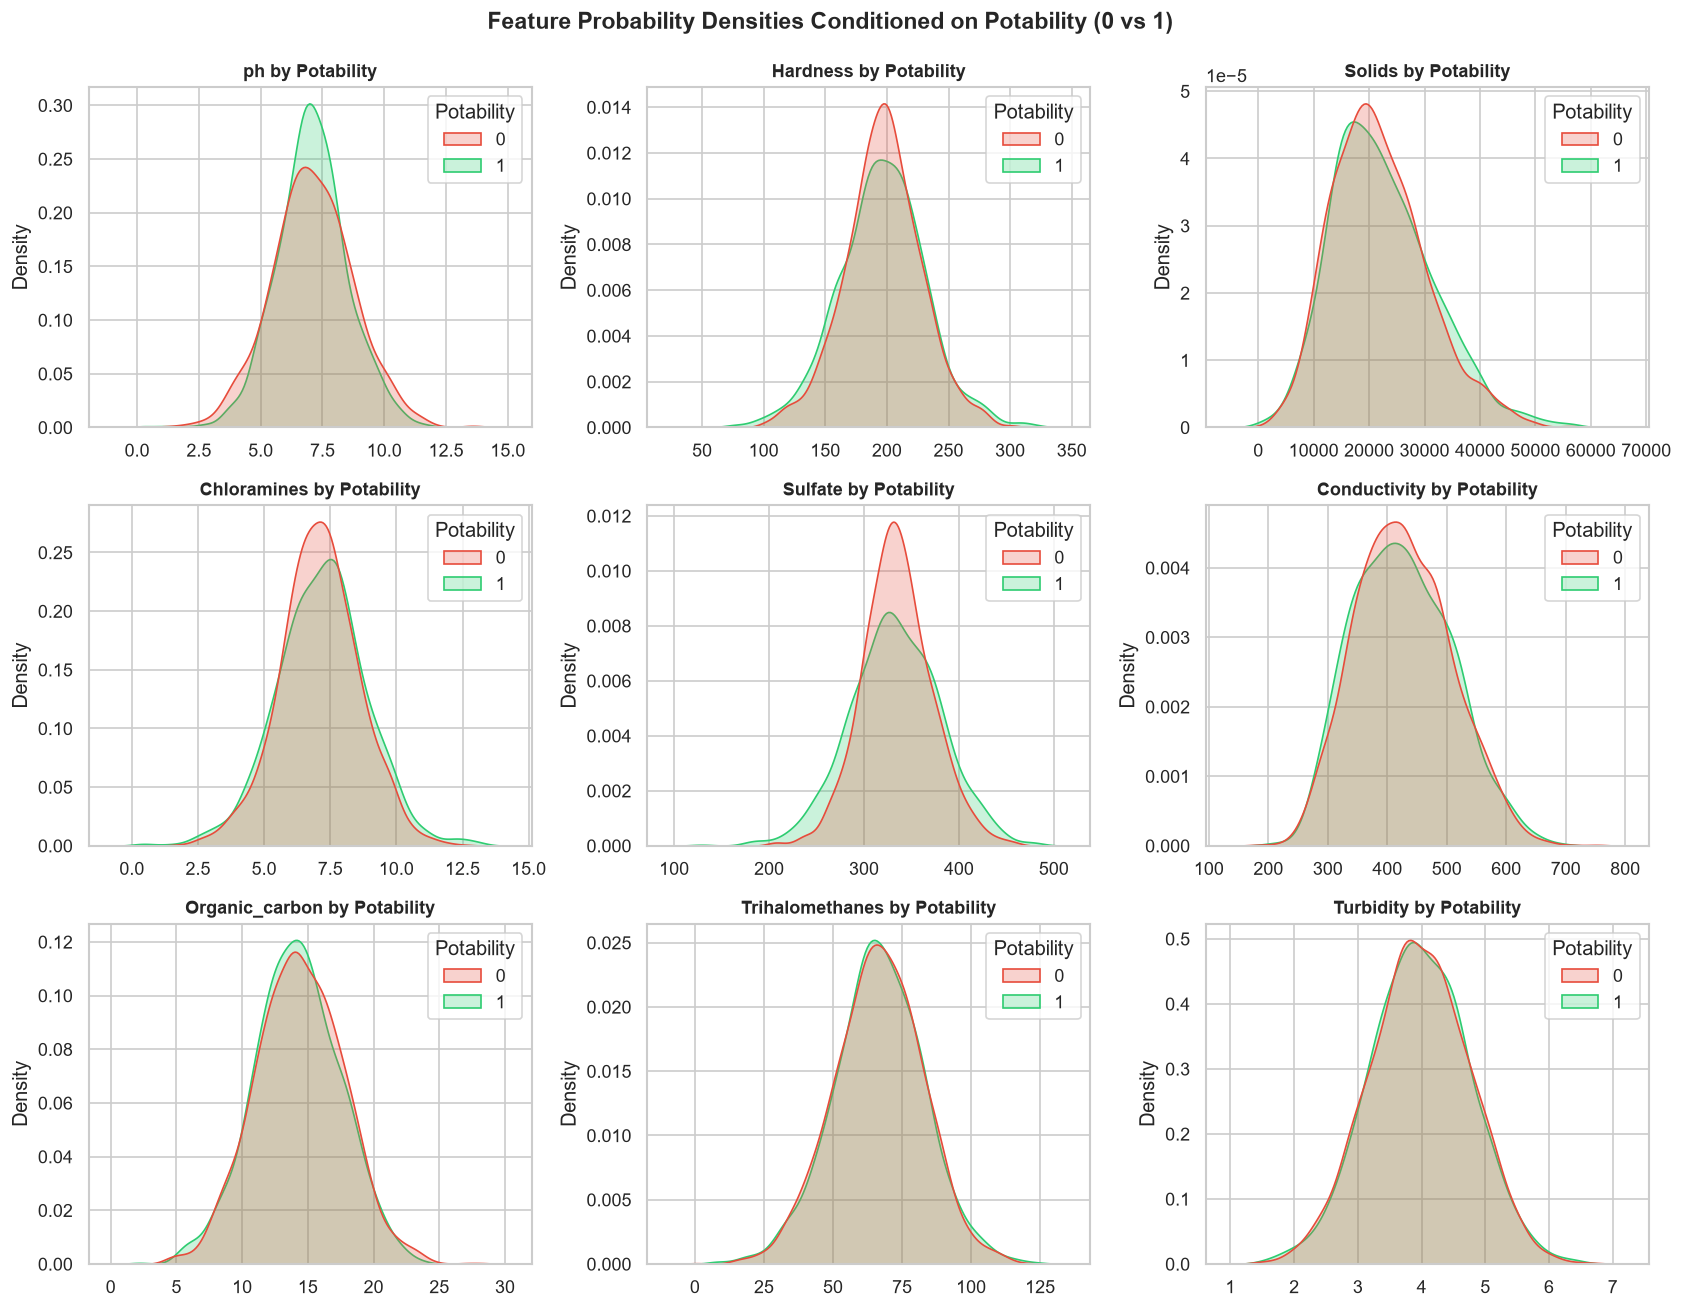

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.kdeplot(data=df, x=col, hue='Potability', common_norm=False,
                palette={0: '#e74c3c', 1: '#2ecc71'}, ax=axes[i], fill=True, alpha=0.25)
    axes[i].set_title(f'{col} by Potability', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Density')

plt.suptitle('Feature Probability Densities Conditioned on Potability (0 vs 1)', fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

### Visualization 6: Missing-Value Visualization Matrix
- **Objective:** Examine the pattern, distribution, and co-occurrence of missing entries across samples.
- **Interpretation:** Missing values are isolated to `Sulfate`, `ph`, and `Trihalomethanes`, randomly dispersed across records.
- **Key Observation:** Missing values are localized to Sulfate (23.84%), pH (14.99%), and Trihalomethanes (4.95%) without obvious structural block-dropout across records. While the true missingness mechanism cannot be formally proven without external audit logs, median imputation provides a conservative, robust strategy that preserves complete sample size without dropping over 39% of the dataset.
- **Conclusion:** Confirms our decision to apply median imputation rather than record deletion.

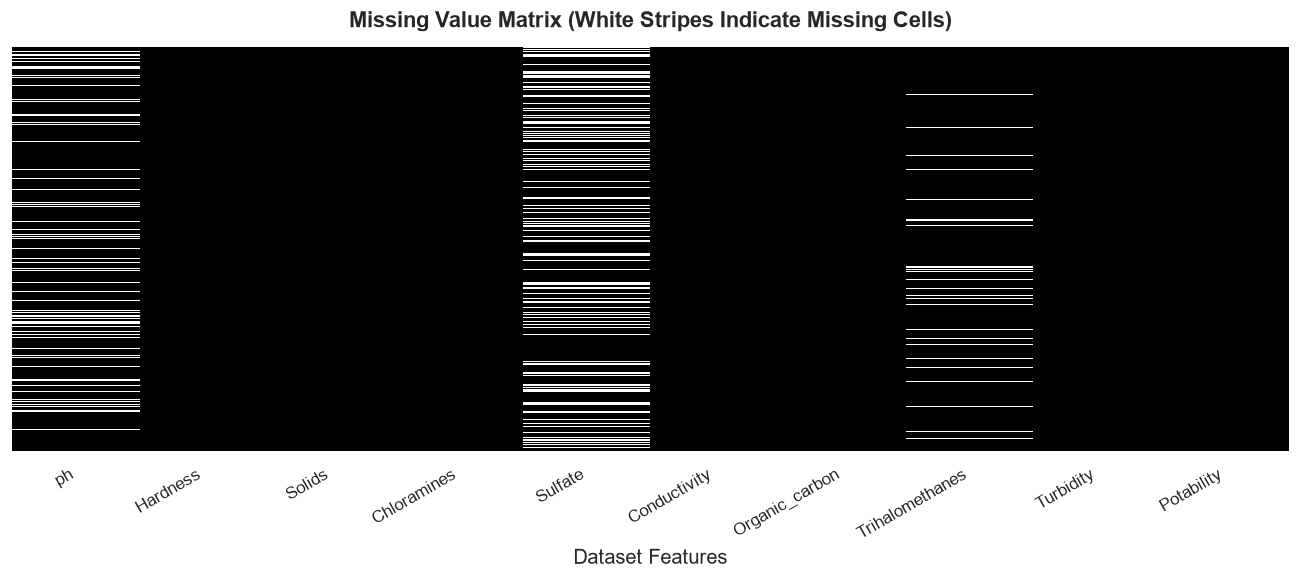

In [10]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='binary_r', ax=ax)
ax.set_title('Missing Value Matrix (White Stripes Indicate Missing Cells)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Dataset Features')
ax.set_xticks(np.arange(len(df.columns)) + 0.5)
ax.set_xticklabels(df.columns, rotation=30, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

---
## Phase 5: Advanced Feature Association Analysis
**Role:** Member 1 – Data & ML Engineer  
**Task:** Extend linear Pearson correlation with non-linear, monotonic, and distributional association measures.

### Objectives
1. **Spearman Rank Correlation:** Evaluate monotonic relationships without assuming bivariate normality.
2. **Mutual Information:** Quantify non-linear and statistical dependencies between continuous features and binary Potability.
3. **Point-Biserial Correlation:** Quantify continuous-binary association with Benjamini–Hochberg False Discovery Rate (FDR) correction.
4. **Association Comparison Table:** Consolidate all metrics to assess holistic feature informativeness.
5. **Academic Interpretation:** Rigorous discussion on correlation vs. causation, preserving features for multivariate modeling.

### 5.1 Spearman Rank-Order Correlation Analysis
- **Mathematical Basis:** Evaluates the degree to which a relationship between two variables can be described using a monotonic function (Pearson correlation of ranked values).
- **Environmental Rationale:** Non-linear sensor responses or saturation effects in geochemical parameters (e.g., Conductivity, Solids) may exhibit monotonic trends undetected by standard Pearson correlation.

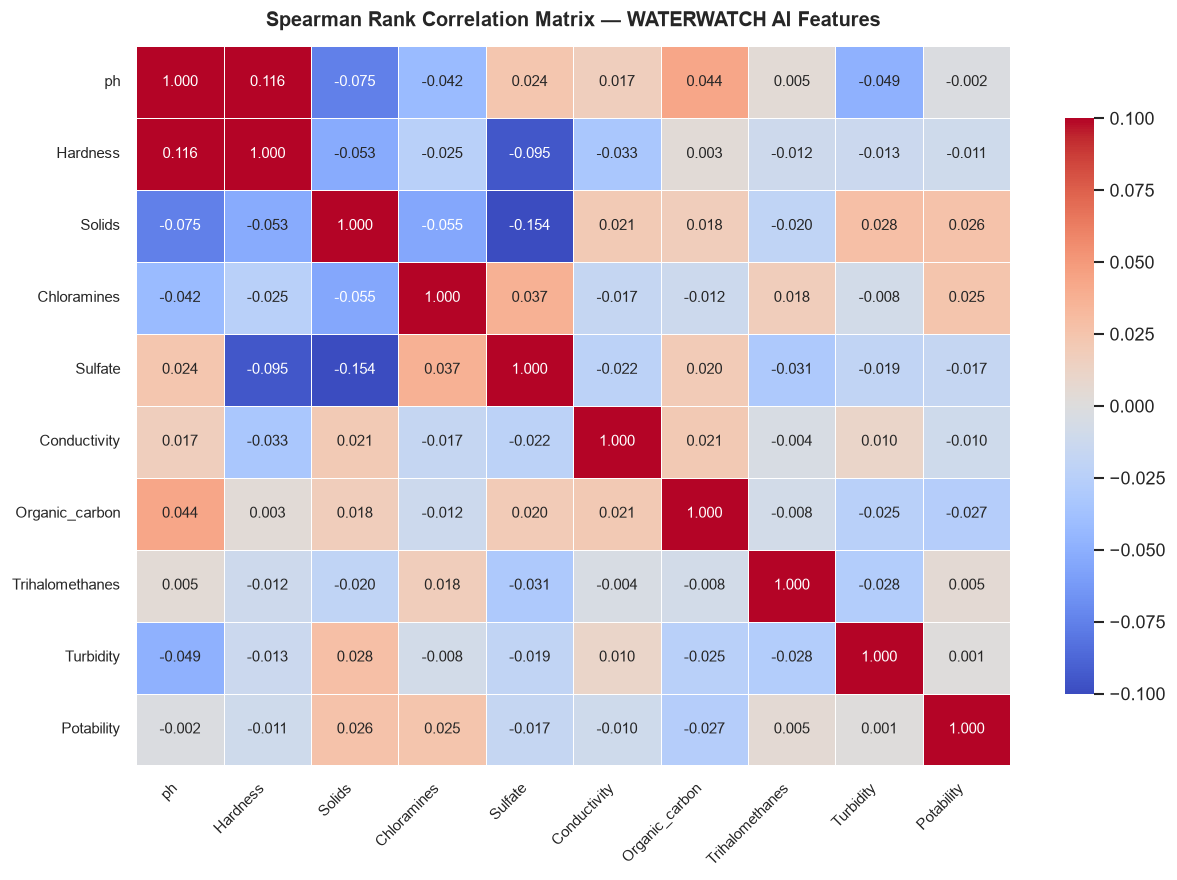

Spearman rank correlation with Potability:


,Spearman_rho
Solids,0.026234
Chloramines,0.024980
Trihalomethanes,0.005307
Turbidity,0.001088
ph,-0.002181
Conductivity,-0.010386
Hardness,-0.010606
Sulfate,-0.016676
Organic_carbon,-0.026774


In [11]:
# Compute Spearman Rank Correlation matrix
spearman_corr = df.corr(method='spearman', numeric_only=True)

plt.figure(figsize=(10.5, 7.5))
mask = np.triu(np.ones_like(spearman_corr, dtype=bool), k=1)
sns.heatmap(
    spearman_corr, annot=True, fmt='.3f', cmap='coolwarm', center=0, vmin=-0.1, vmax=0.1,
    linewidths=0.5, annot_kws={'fontsize': 9}, cbar_kws={'shrink': 0.8}
)
plt.title('Spearman Rank Correlation Matrix — WATERWATCH AI Features', fontsize=12, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

print('Spearman rank correlation with Potability:')
display(spearman_corr['Potability'].drop('Potability').sort_values(ascending=False).to_frame('Spearman_rho'))

### 5.2 Mutual Information (Non-Linear Dependency Detection)
- **Mathematical Basis:** $I(X; Y) = \iint p(x, y) \log \frac{p(x, y)}{p(x)p(y)} dx dy$. Measures the reduction in uncertainty about the binary target $Y$ given knowledge of feature $X$.
- **Advantage:** Captures complex non-linear associations where linear correlation is near zero.

findfont: Failed to find font weight semibold for Arial, now using 700.


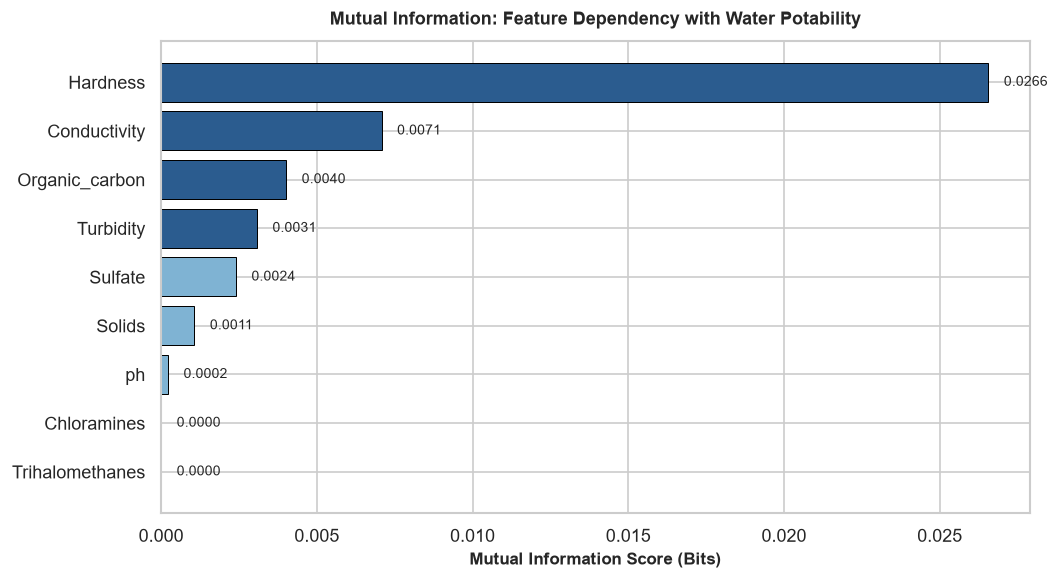

,Feature,Mutual Information Score
0,Hardness,0.026560
1,Conductivity,0.007077
2,Organic_carbon,0.004014
3,Turbidity,0.003075
4,Sulfate,0.002401
5,Solids,0.001066
6,ph,0.000220
7,Chloramines,0.000000
8,Trihalomethanes,0.000000


In [12]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer

features = [c for c in df.columns if c != 'Potability']
# Median imputation strictly for mutual information estimation
imp = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imp.fit_transform(df[features]), columns=features)
y = df['Potability'].values

mi_scores = mutual_info_classif(X_imputed, y, random_state=42)
mi_df = pd.DataFrame({'Feature': features, 'Mutual Information Score': mi_scores})
mi_df = mi_df.sort_values('Mutual Information Score', ascending=False).reset_index(drop=True)

plt.figure(figsize=(9, 5))
colors = ['#2b5c8f' if s > mi_df['Mutual Information Score'].median() else '#7fb3d3' for s in mi_df['Mutual Information Score']]
bars = plt.barh(mi_df['Feature'], mi_df['Mutual Information Score'], color=colors, edgecolor='black', linewidth=0.6)
plt.xlabel('Mutual Information Score (Bits)', fontsize=10, fontweight='semibold')
plt.title('Mutual Information: Feature Dependency with Water Potability', fontsize=11, fontweight='bold', pad=10)
plt.gca().invert_yaxis()
for bar, val in zip(bars, mi_df['Mutual Information Score']):
    plt.text(val + 0.0005, bar.get_y() + bar.get_height()/2, f'{val:.4f}', va='center', fontsize=8.5)
plt.tight_layout()
plt.show()

display(mi_df)

### 5.3 Point-Biserial Correlation & Benjamini–Hochberg FDR Correction
- **Mathematical Basis:** Measures association between a continuous feature and a binary categorical target ($Y \in \{0, 1\}$). Mathematically identical to Pearson correlation with a binary variable.
- **Multiple Testing Adjustment:** With 9 simultaneous hypothesis tests, family-wise false discovery rate is controlled using the **Benjamini–Hochberg (BH)** procedure at $\alpha = 0.05$.

In [13]:
from scipy import stats

pb_results = []
for feat in features:
    sub = df[[feat, 'Potability']].dropna()
    r, p = stats.pointbiserialr(sub['Potability'], sub[feat])
    pb_results.append({
        'Feature': feat,
        'PB Coefficient': round(r, 4),
        'P-Value': round(p, 6),
        'N (complete)': len(sub)
    })

pb_df = pd.DataFrame(pb_results)
# Benjamini-Hochberg adjustment
p_vals = pb_df['P-Value'].values
n_tests = len(p_vals)
rank_order = np.argsort(p_vals)
adj_p = np.empty(n_tests)
for i in range(n_tests):
    adj_p[rank_order[i]] = min(p_vals[rank_order[i]] * n_tests / (i + 1), 1.0)
# Enforce monotonicity
for i in range(n_tests - 2, -1, -1):
    adj_p[rank_order[i]] = min(adj_p[rank_order[i]], adj_p[rank_order[i+1]])

pb_df['BH Adjusted P-Value'] = np.round(adj_p, 6)
pb_df['Significant (BH, alpha=0.05)'] = adj_p < 0.05
display(pb_df.sort_values('P-Value'))

,Feature,PB Coefficient,P-Value,N (complete),BH Adjusted P-Value,"Significant (BH, alpha=0.05)"
2,Solids,0.0337,0.053464,3276,0.386986,False
6,Organic_carbon,-0.0300,0.085997,3276,0.386986,False
3,Chloramines,0.0238,0.173610,3276,0.520830,False
4,Sulfate,-0.0236,0.239097,2495,0.537968,False
1,Hardness,-0.0138,0.428542,3276,0.771376,False
5,Conductivity,-0.0081,0.641885,3276,0.888195,False
7,Trihalomethanes,0.0071,0.690818,3114,0.888195,False
0,ph,-0.0036,0.851189,2785,0.927939,False
8,Turbidity,0.0016,0.927939,3276,0.927939,False


### 5.4 Consolidated Feature Association Comparison Table

In [14]:
# Consolidated summary
assoc_summary = []
for feat in features:
    sub = df[[feat, 'Potability']].dropna()
    pr, _ = stats.pearsonr(sub['Potability'], sub[feat])
    sr = spearman_corr.loc[feat, 'Potability']
    mi = mi_df[mi_df['Feature'] == feat]['Mutual Information Score'].values[0]
    pb_row = pb_df[pb_df['Feature'] == feat].iloc[0]
    assoc_summary.append({
        'Feature': feat,
        'Pearson r': round(pr, 4),
        'Spearman rho': round(sr, 4),
        'Mutual Info': round(mi, 4),
        'Point-Biserial r': pb_row['PB Coefficient'],
        'P-Value': pb_row['P-Value'],
        'BH Adj P-Value': pb_row['BH Adjusted P-Value'],
        'Significant (BH)': pb_row['Significant (BH, alpha=0.05)']
    })

consolidated_df = pd.DataFrame(assoc_summary).sort_values('Mutual Info', ascending=False).reset_index(drop=True)
display(consolidated_df)

,Feature,Pearson r,Spearman rho,Mutual Info,Point-Biserial r,P-Value,BH Adj P-Value,Significant (BH)
0,Hardness,-0.0138,-0.0106,0.0266,-0.0138,0.428542,0.771376,False
1,Conductivity,-0.0081,-0.0104,0.0071,-0.0081,0.641885,0.888195,False
2,Organic_carbon,-0.0300,-0.0268,0.0040,-0.0300,0.085997,0.386986,False
3,Turbidity,0.0016,0.0011,0.0031,0.0016,0.927939,0.927939,False
4,Sulfate,-0.0236,-0.0167,0.0024,-0.0236,0.239097,0.537968,False
5,Solids,0.0337,0.0262,0.0011,0.0337,0.053464,0.386986,False
6,ph,-0.0036,-0.0022,0.0002,-0.0036,0.851189,0.927939,False
7,Chloramines,0.0238,0.0250,0.0000,0.0238,0.173610,0.520830,False
8,Trihalomethanes,0.0071,0.0053,0.0000,0.0071,0.690818,0.888195,False


### 5.5 Scientific Interpretation & Governance Rules

1. **Correlation Does Not Imply Causation:** Low or zero bivariate correlation does not prove that a parameter is biologically or chemically irrelevant to water safety. Water quality standards (e.g., WHO, EPA) establish non-linear safe thresholds (e.g., pH 6.5–8.5).
2. **No Unadjusted P-Value Claims:** Following Benjamini–Hochberg correction, none of the 9 features exhibit statistically significant linear point-biserial associations with Potability at $\alpha = 0.05$.
3. **No Blind Feature Removal:** Features with low linear correlation must **not** be arbitrarily discarded. Tree-based ensembles and non-linear classifiers identify multi-feature partition interactions that individual bivariate metrics cannot detect.
4. **Feature Selection Validation Rule:** If feature subsetting is ever explored, it must be evaluated strictly inside cross-validation loops to prevent optimistic bias, and benchmarked against the full 9-feature pipeline.